# Sampler interface

This notebook provides the interface with `Cobaya` to run an MCMC parameter inference on the mock datasets generated with `horizon`.

## Import packages

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from chainconsumer import Chain, ChainConsumer, PlotConfig

from tools.utilities import Utilities

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif"
})

green        = ['#a6dba0','#5aae61','#1b7837']
purple       = ['#c2a5cf', '#9970ab', '#762a83']
analogous    = ['#a0c3db', '#dbb7a0']
warm         = ['#fdcc8a', '#fc8d59', '#d7301f']
cool         = ['#41b6c4', '#2c7fb8', '#253494']

### Detect settings from datafile

In [2]:
# find all datasets
datasets, unmatched = Utilities.list_mock_datasets()

# show them
Utilities.print_mock_datasets(datasets, unmatched)

[0] M2 A=-0.075 B=-0.01 n_QSO=100
[1] M2 A=-0.075 B=-0.01 n_QSO=200


In [3]:
# select by index in the list above, returns a dictionary of that dataset's settings
dataset = Utilities.select_mock_dataset(index=1, datasets=datasets)

### Run Cobaya

In [4]:
from cobaya.run import run
from likelihood import DDRlike

info = {
    'params': {
        'A': {
            'prior': {'min': -0.2, 'max': 0.2},
            'ref': {'dist': 'norm', 'loc': dataset['A'], 'scale': 0.1},
            'proposal': 0.05,
            'latex': 'A'
        },
        
        # ==========================================
        # OPTION 1: Parameter B is FIXED to 0
        # ==========================================
        #'B': 0,

        # ==========================================
        # OPTION 2: Parameter B is SAMPLED 
        # (Uncomment this block and delete the 'B': 0 line above to use)
        # ==========================================
         'B': {
             'prior': {'min': -0.1, 'max': 0.1},
             'ref': {'dist': 'norm', 'loc': 0.0, 'scale': 0.05},
             'proposal': 0.005,
             'latex': 'B'
         },
        'sigma_int': {
             'prior': {'min': 0.0, 'max': 0.5},
             'ref': {'dist': 'norm', 'loc': 0.2, 'scale': 0.05},
             'proposal': 0.02,
             'latex': r'\sigma_{\rm int}'
         }
    },
    'sampler': {
        'mcmc': {'max_tries': 10000, 'Rminus1_stop': 0.1}
    },
    'output': 'chains/' + dataset['settings'],
    'likelihood': {
        'DDRlike': {
            'external': DDRlike,
            'model': dataset['model'],  # Set DDR violation model
            'datapath': './mock_data/' + dataset['settings']
        }
    },
    'force': True
}

info['debug'] = False

# Run MCMC sampling
updated_info, sampler = run(info)

[output] Output to be read-from/written-into folder 'chains', with prefix 'M2A-0.075B-0.01nQSO200'
[output] Found existing info files with the requested output prefix: 'chains/M2A-0.075B-0.01nQSO200'
[output] Will delete previous products ('force' was requested).
[mcmc] Getting initial point... (this may take a few seconds)
[mcmc] Initial point: A:0.1556701, B:-0.001478926, sigma_int:0.2225598
[model] Measuring speeds... (this may take a few seconds)
[model] Setting measured speeds (per sec): {DDRlike: 55500.0}
[mcmc] Covariance matrix not present. We will start learning the covariance of the proposal earlier: R-1 = 30 (would be 2 if all params loaded).
[mcmc] Sampling!
[mcmc] Progress @ 2026-03-26 12:45:20 : 1 steps taken, and 0 accepted.
[mcmc] Learn + convergence test @ 120 samples accepted.
[mcmc]  - Acceptance rate: 0.138
[mcmc]  - Convergence of means: R-1 = 13.018383 after 96 accepted steps
[mcmc]  - Updated covariance matrix of proposal pdf.
[mcmc] Learn + convergence test @ 24

### Plot contours with chainconsumer

Available columns: ['weight', 'minuslogpost', 'A', 'B', 'sigma_int', 'minuslogprior', 'minuslogprior__0', 'chi2', 'chi2__DDRlike']
Chain shape: (1080, 9)



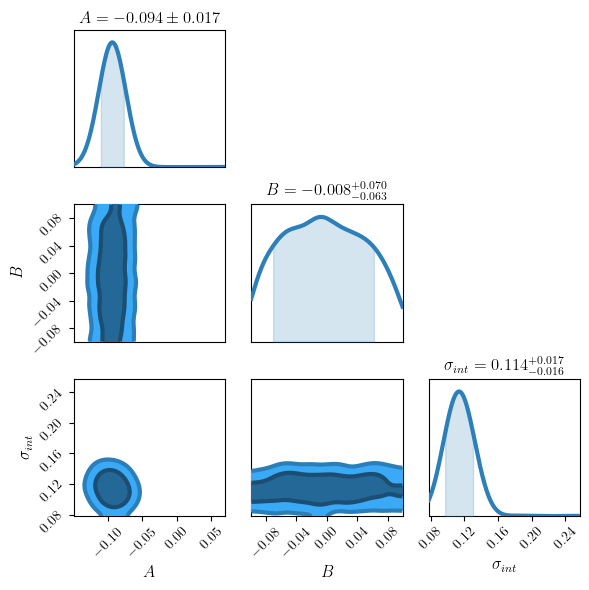

In [5]:
# Read the chain file from Cobaya output
chain_file = 'chains/'+dataset['settings']+'.1.txt'

# Read the header line to get column names
with open(chain_file, 'r') as f:
    header_line = f.readline()

# Extract column names from the header (remove # and split)
column_names = header_line.strip('#').split()

# Read the chain data with explicit column names
df = pd.read_csv(chain_file, sep=r'\s+', comment='#', names=column_names, header=None)

# Print available columns for debugging
print("Available columns:", df.columns.tolist())
print(f"Chain shape: {df.shape}")
print()

# Extract parameters for the triangle plot
params = ['A', 'B', 'sigma_int']
weights = df['weight'].values

# Create ChainConsumer object
c = ChainConsumer()

# Add the chain with proper column names and weights
c.add_chain(Chain(samples=df[params], weights=weights, name="DDR", 
                  bins=10, smooth=20,
                  shade_gradient=0.8, linewidth=3, color=cool[1]))

c.set_plot_config(PlotConfig(labels={'A': r'$A$', 'B': r'$B$', 'sigma_int': r'$\sigma_{int}$'}, 
                            usetex=True,serif=True))

# Generate triangle plot
fig = c.plotter.plot(figsize=(6,6))

# Adjust layout for better display
plt.tight_layout()
plt.show()

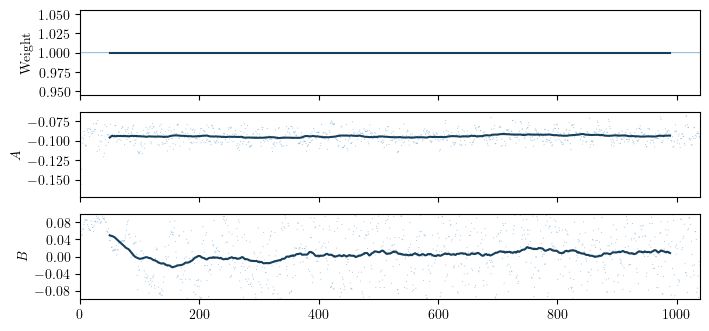

In [6]:
fig = c.plotter.plot_walks(convolve=100)